# Volatility-Managed Equity + Defensive Pair Overlay — Backtest Notebook
**2270 Financial Modeling, Nova SBE — Group assignment**

**Moodle group:** _TODO: group name_
**Members:** _TODO: names + student numbers_
**GitHub repository:** https://github.com/Ben10Nova/FinancialModellingGroupN
**Streamlit app:** _TODO: deployed URL_

This notebook reproduces every number, table and figure in the prospectus.

### Setup
1. Open in Google Colab (colab.research.google.com) → *File → Upload notebook*.
2. *Runtime → Run all*. No data files are needed: all data is downloaded from the Yahoo Finance API via `yfinance`. Runtime ≈ 1–2 minutes.
3. Sample period and every assumption are set explicitly in the **Parameters** cell.

### Strategy in one paragraph
**Sleeve 1 – volatility-managed S&P 500.** At each month-end we measure SPY's realised volatility over the last 21 trading days and hold `15% / realised vol` of capital in SPY (capped at 2×). The remainder sits in T-bills (or is borrowed at T-bill + 0.5% when exposure > 100%).
**Sleeve 2 – XLU/XLP pair overlay.** Utilities (XLU) and consumer staples (XLP) are both defensive sectors and normally move together. Each day we compute the z-score of `log(XLU/XLP)` versus its 60-day mean. If z > 2 we short XLU and buy XLP (100% of capital each); if z < −2 the reverse; we close when |z| < 0.5. The overlay is long/short, so it is (approximately) market neutral.

In [1]:
%pip install -q yfinance statsmodels
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, yfinance as yf
pd.set_option('display.width', 200)
print('yfinance', yf.__version__, '| pandas', pd.__version__)

Note: you may need to restart the kernel to use updated packages.


yfinance 1.8.0 | pandas 3.0.5


## 1. Parameters (all assumptions in one place)

In [2]:
START, END = '2006-01-01', '2025-12-31'   # evaluation window: first and last return day (inclusive)
DATA_START = '2005-06-01'                 # warm-up history so the 60-day and 21-day windows exist on day 1
IS_END = '2015-12-31'                     # split for the in-sample / out-of-sample check

# Sleeve 1: volatility-managed SPY
TARGET_VOL = 0.15     # annualised volatility target
VOL_DAYS   = 21       # look-back for realised volatility (~1 month)
MAX_LEV    = 2.0      # cap on SPY exposure

# Sleeve 2: pair overlay
PAIR_A, PAIR_B = 'XLU', 'XLP'
Z_WIN, Z_IN, Z_OUT = 60, 2.0, 0.5
PAIR_SIZE = 1.0       # notional per leg as a fraction of equity

# Implementation costs
COST       = 0.0010   # 10 bp of notional traded (spread + commission + slippage)
FIN_SPREAD = 0.0050   # borrowing cost above the T-bill rate, p.a.
SHORT_FEE  = 0.0025   # stock-borrow fee on short notional, p.a.

TICKERS = ['SPY', 'XLU', 'XLP', '^SP500TR', '^IRX']

## 2. Data
* **Source:** Yahoo Finance through the `yfinance` API.
* **Adjustment:** `auto_adjust=True` → prices are adjusted for splits **and dividends**, so returns are total returns.
* **Benchmark:** `^SP500TR`, the S&P 500 total-return index (dividends reinvested).
* **Risk-free rate:** `^IRX`, the 13-week US T-bill yield (% p.a.). Daily rf = yield / 100 / 252, using the yield known at the previous close.
* **Frequency:** daily data for signals and trading; monthly returns (compounded from daily) for the performance statistics.

In [3]:
raw = yf.download(TICKERS, start=DATA_START, end=pd.Timestamp(END) + pd.Timedelta(days=1),
                  auto_adjust=True, progress=False)['Close'][TICKERS]

# The four checks from Lecture 3: shape, date range, missing values, plot
print('shape:', raw.shape)
print('date range:', raw.index.min().date(), '->', raw.index.max().date())
print('missing values per column:\n', raw.isna().sum().to_string())

shape: (5180, 5)
date range: 2005-06-01 -> 2025-12-31
missing values per column:
 Ticker
SPY         0
XLU         0
XLP         0
^SP500TR    0
^IRX        5


dropna removed 0 of 5180 rows; sample now 2005-06-01 -> 2025-12-31


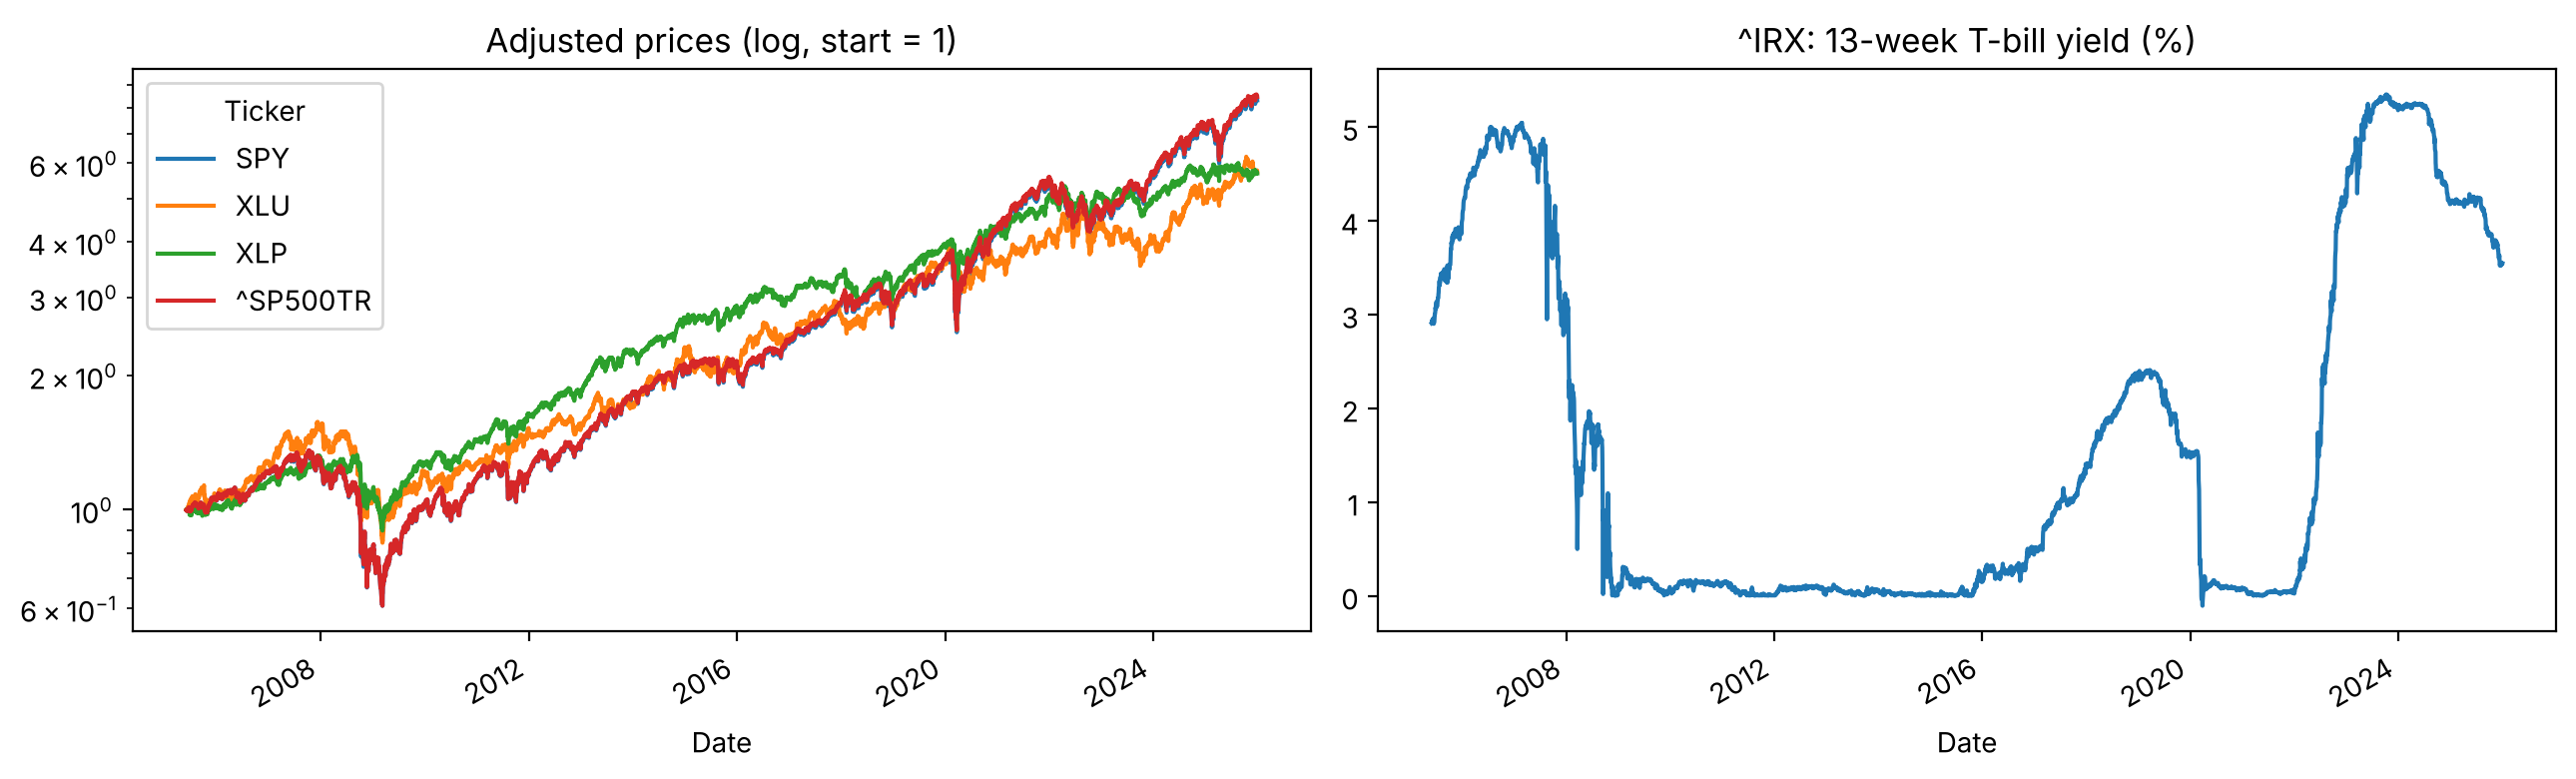

In [4]:
px = raw.copy()
px['^IRX'] = px['^IRX'].ffill()           # T-bill quote occasionally missing on a trading day: carry last yield
n0 = len(px)
px = px.dropna()
print(f'dropna removed {n0 - len(px)} of {n0} rows; sample now {px.index.min().date()} -> {px.index.max().date()}')
assert px.index.min() < pd.Timestamp(START) and px.index.max() == pd.Timestamp(END), 'sample does not cover START..END'

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(px.drop(columns='^IRX') / px.drop(columns='^IRX').iloc[0]).plot(ax=ax[0], logy=True, title='Adjusted prices (log, start = 1)')
px['^IRX'].plot(ax=ax[1], title='^IRX: 13-week T-bill yield (%)')
plt.tight_layout(); plt.show()

In [5]:
ret = px[['SPY', 'XLU', 'XLP', '^SP500TR']].pct_change()
rf_d = (px['^IRX'] / 100 / 252).shift(1)     # yield known at t-1 is earned on day t

# Sanity check: SPY (adjusted) vs the S&P 500 total-return index should differ only by SPY's ~0.09% fee
yr = (1 + ret.loc[START:END, ['SPY', '^SP500TR']]).groupby(lambda d: d.year).prod() - 1
print('mean annual return SPY vs ^SP500TR:', yr.mean().round(4).to_dict(),
      '| correlation of daily returns:', round(ret.loc[START:END, 'SPY'].corr(ret.loc[START:END, '^SP500TR']), 4))

mean annual return SPY vs ^SP500TR: {'SPY': 0.1243, '^SP500TR': 0.1252} | correlation of daily returns: 0.9938


## 3. Signals
Both signals use only prices up to and including the close of day *t*. Trades happen at that close, so the first return a new position can earn is day *t+1* (Lecture 4: `position.shift(1) * return`).

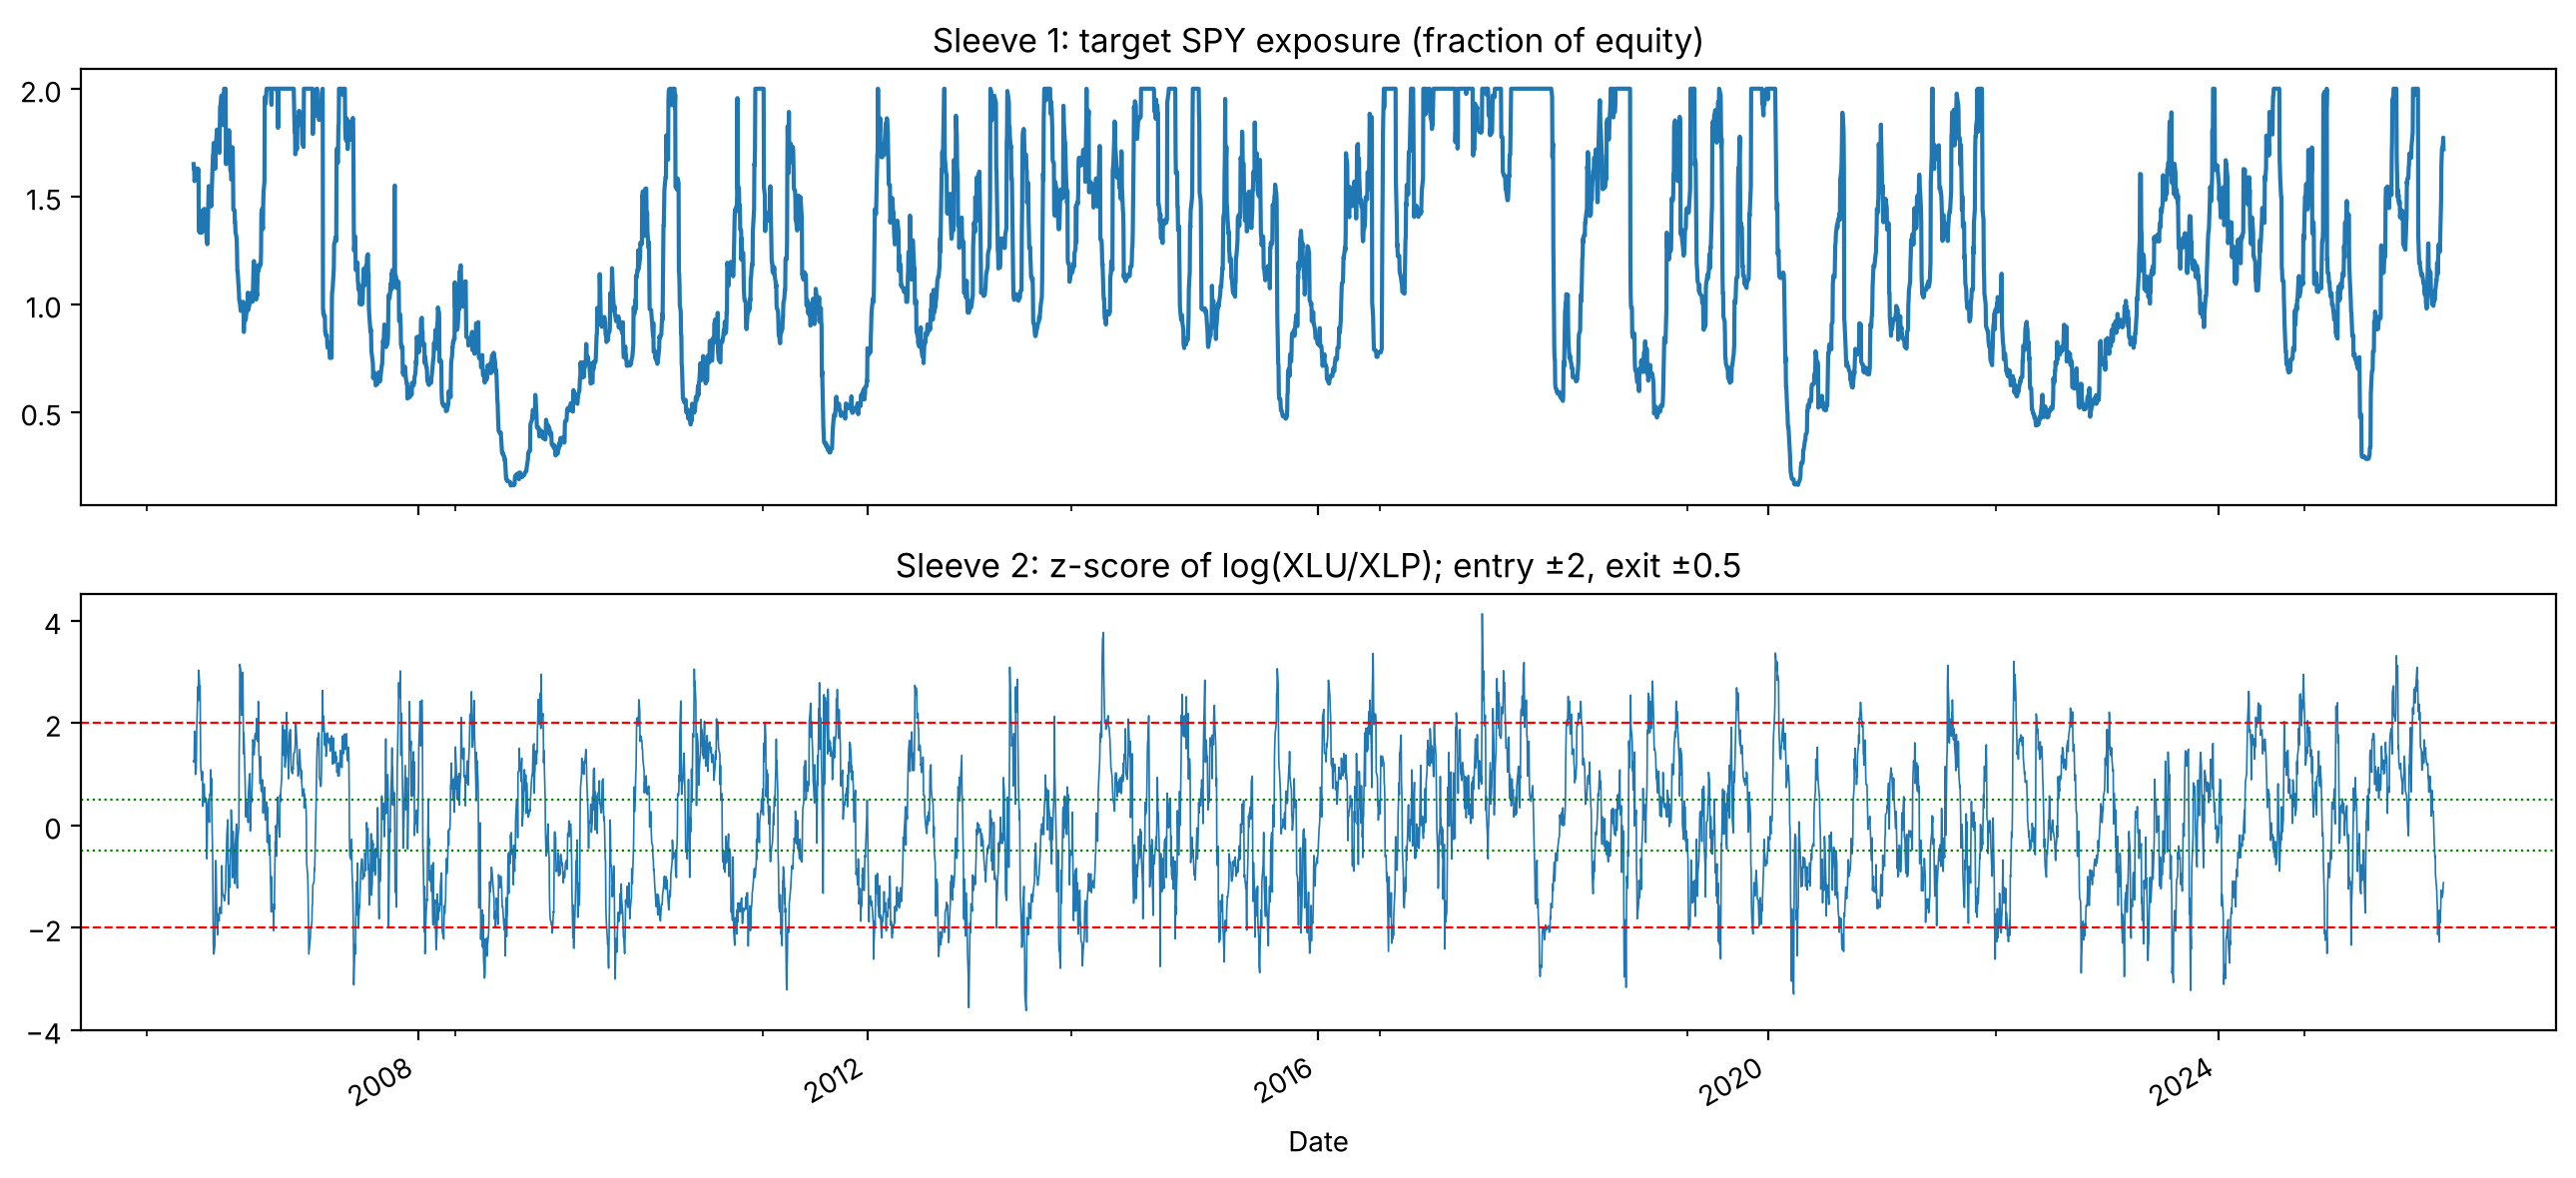

pair position open on 42% of days


In [6]:
def spy_exposure(px):
    vol = px['SPY'].pct_change().rolling(VOL_DAYS).std() * np.sqrt(252)   # trailing window ending at t
    return (TARGET_VOL / vol).clip(upper=MAX_LEV)

def pair_position(px, win=Z_WIN, z_in=Z_IN, z_out=Z_OUT):
    s = np.log(px[PAIR_A] / px[PAIR_B])
    z = (s - s.rolling(win).mean()) / s.rolling(win).std()                 # trailing window ending at t
    pos, p = [], 0
    for zt in z:
        if np.isnan(zt):                 p = 0
        elif p == 0 and zt >  z_in:      p = -1   # XLU rich vs XLP: short XLU, long XLP
        elif p == 0 and zt < -z_in:      p = +1   # XLU cheap vs XLP: long XLU, short XLP
        elif p != 0 and abs(zt) < z_out: p = 0    # spread has reverted: close
        pos.append(p)
    return pd.Series(pos, index=z.index, dtype=float), z

expo = spy_exposure(px)
pos, z = pair_position(px)

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
expo.loc[START:END].plot(ax=ax[0], title='Sleeve 1: target SPY exposure (fraction of equity)')
z.loc[START:END].plot(ax=ax[1], lw=.6, title='Sleeve 2: z-score of log(XLU/XLP); entry ±2, exit ±0.5')
for h in [Z_IN, -Z_IN]: ax[1].axhline(h, c='r', ls='--', lw=.8)
for h in [Z_OUT, -Z_OUT]: ax[1].axhline(h, c='g', ls=':', lw=.8)
plt.tight_layout(); plt.show()
print(f'pair position open on {(pos.loc[START:END] != 0).mean():.0%} of days')

## 4. Backtest engine
We simulate the account day by day, holding positions between trades:

1. Weights set at the close of day *t−1* earn day *t*'s returns. Uninvested cash earns the T-bill rate; borrowed cash pays T-bill + 0.5%; short notional pays a 0.25% p.a. borrow fee.
2. Positions then **drift** with prices. There is no hidden daily rebalancing.
3. At the close of day *t* the strategy trades only (a) on the last trading day of each month, to reset SPY exposure, and (b) when the pair signal opens or closes a trade.
4. Transaction cost = `COST × |target weight − drifted weight|`, summed over assets. Turnover is reported.

`lag=2` delays every trade by one extra day (signal at close *t*, trade at close *t+1*) as a robustness check.

In [7]:
def backtest(px, use_spy=True, pair_size=PAIR_SIZE, cost=COST, lag=1, pair_kw={}):
    e = spy_exposure(px) if use_spy else pd.Series(0.0, index=px.index)
    p, _ = pair_position(px, **pair_kw)
    month_end = px.index.to_series().groupby(px.index.to_period('M')).transform('max') == px.index
    e, p, month_end = e.shift(lag - 1), p.shift(lag - 1), month_end.shift(lag - 1, fill_value=False)

    i0 = px.index.searchsorted(pd.Timestamp(START)) - 1          # last close before START: initial trade
    idx = px.index[i0:][px.index[i0:] <= pd.Timestamp(END)]
    R = px[['SPY', PAIR_A, PAIR_B]].pct_change().loc[idx].values
    rf, e, p, me = rf_d.loc[idx].values, e.loc[idx].values, p.loc[idx].fillna(0).values, month_end.loc[idx].values

    w, prev_p, rows = np.zeros(3), 0.0, []
    for i in range(len(idx)):
        if i == 0:
            gross, w_drift = 0.0, w.copy()                           # nothing held before the first close
        else:
            cash = 1 - w.sum()
            gross = w @ R[i] + cash * (rf[i] + (FIN_SPREAD / 252 if cash < 0 else 0)) \
                    - np.abs(np.minimum(w, 0)).sum() * SHORT_FEE / 252
            w_drift = w * (1 + R[i]) / (1 + gross)
        tgt = w_drift.copy()
        if i == 0 or me[i]:
            tgt[0] = e[i]
        if p[i] != prev_p:
            tgt[1], tgt[2] = p[i] * pair_size, -p[i] * pair_size
            prev_p = p[i]
        turn = np.abs(tgt - w_drift).sum()
        rows.append((gross, gross - turn * cost, turn, tgt[0], np.abs(tgt).sum()))
        w = tgt
    out = pd.DataFrame(rows, index=idx, columns=['gross', 'net', 'turnover', 'w_spy', 'gross_exposure'])
    return out.iloc[1:]                                           # returns start on the first day after START's close

bt = backtest(px)
print(bt.describe().T[['mean', 'min', 'max']])

                    mean       min       max
gross           0.000854 -0.074777  0.103066
net             0.000753 -0.074777  0.103066
turnover        0.100108  0.000000  2.595101
w_spy           1.202002  0.129527  2.165231
gross_exposure  2.044576  0.129527  4.426773


## 5. No look-ahead proof (truncation test)
If any calculation used future data, deleting the future would change the past. We delete every price after a cutoff date and assert that signals and strategy returns up to that date are **identical**.

In [8]:
for cut in ['2010-06-30', '2015-12-31', '2020-03-31']:
    px_cut = px.loc[:cut]
    assert np.allclose(spy_exposure(px).loc[:cut].dropna(), spy_exposure(px_cut).dropna())
    assert (pair_position(px)[0].loc[:cut] == pair_position(px_cut)[0]).all()
    full, trunc = backtest(px).loc[:cut], backtest(px_cut)
    assert np.allclose(full.values, trunc.values), cut
    print(f'cut-off {cut}: signals and {len(trunc)} daily returns identical with and without future data ✓')

cut-off 2010-06-30: signals and 1131 daily returns identical with and without future data ✓


cut-off 2015-12-31: signals and 2517 daily returns identical with and without future data ✓


cut-off 2020-03-31: signals and 3585 daily returns identical with and without future data ✓


**Why dividend-adjusted prices do not leak information into the pair signal.** `auto_adjust=True` rescales all prices *before* each dividend by a factor. Inside the 60-day z-score window, factors from dividends paid *after* day *t* multiply every price in the window equally. They add a constant to `log(XLU/XLP)` and cancel out of `(s − mean)/std`. Factors from dividends inside the window are known at *t*. The truncation test above confirms this numerically.

## 6. Performance vs. benchmark

In [9]:
monthly = lambda r: (1 + r).resample('ME').prod() - 1
bench_d = ret['^SP500TR'].loc[bt.index]
rf_m = monthly(rf_d.loc[bt.index])
bench_m = monthly(bench_d)

def stats(r_m):
    # Monthly-return statistics. Means x12, volatilities x sqrt(12); beta not annualised.
    rf, b = rf_m.loc[r_m.index], bench_m.loc[r_m.index]
    ex, bex = r_m - rf, b - rf
    ols = sm.OLS(ex, sm.add_constant(bex)).fit()
    a, beta = ols.params.iloc[0], ols.params.iloc[1]
    wealth = (1 + r_m).cumprod()
    return pd.Series({
        'Ann. avg return': r_m.mean() * 12,
        'Ann. volatility': r_m.std() * np.sqrt(12),
        'Sharpe ratio': ex.mean() / ex.std() * np.sqrt(12),
        'Alpha (ann.)': a * 12,
        'Alpha t-stat': ols.tvalues.iloc[0],
        'Beta': beta,
        'Information ratio': a / ols.resid.std() * np.sqrt(12),
        'Max drawdown (monthly)': (wealth / wealth.cummax() - 1).min(),
    })

strat_m = monthly(bt.net)
table = pd.DataFrame({'Strategy (net)': stats(strat_m), 'Strategy (gross)': stats(monthly(bt.gross)),
                      'S&P 500 TR': stats(bench_m)})
table.loc[['Alpha t-stat', 'Information ratio'], 'S&P 500 TR'] = np.nan   # benchmark regressed on itself: undefined
print(f'{len(strat_m)} monthly observations, {strat_m.index[0]:%Y-%m} to {strat_m.index[-1]:%Y-%m}')
table.round(4)

240 monthly observations, 2006-01 to 2025-12


,Strategy (net),Strategy (gross),S&P 500 TR
Ann. avg return,0.1820,0.2075,0.1163
Ann. volatility,0.1590,0.1593,0.1509
Sharpe ratio,1.0427,1.2007,0.6630
Alpha (ann.),0.0809,0.1070,-0.0000
Alpha t-stat,3.7624,4.8833,NaN
Beta,0.8485,0.8422,1.0000
Information ratio,0.8584,1.1142,NaN
Max drawdown (monthly),-0.2997,-0.2890,-0.5095


**Calculation assumptions**
* Statistics use monthly returns compounded from daily returns: 240 months, January 2006 to December 2025.
* Annualised average return = mean monthly return × 12. Volatility = monthly std × √12.
* Sharpe = mean(R − Rf) / std(R − Rf) × √12, with Rf from ^IRX.
* Alpha and beta come from the OLS regression R − Rf = α + β (R_SP500TR − Rf) + ε. Alpha is annualised (×12); **beta is not**.
* Information ratio = α / σ(ε) × √12, i.e. alpha per unit of residual (benchmark-unrelated) risk.
* Net returns include 10 bp per unit traded, T-bill + 0.5% on borrowed cash, and a 0.25% p.a. short-borrow fee. No taxes.

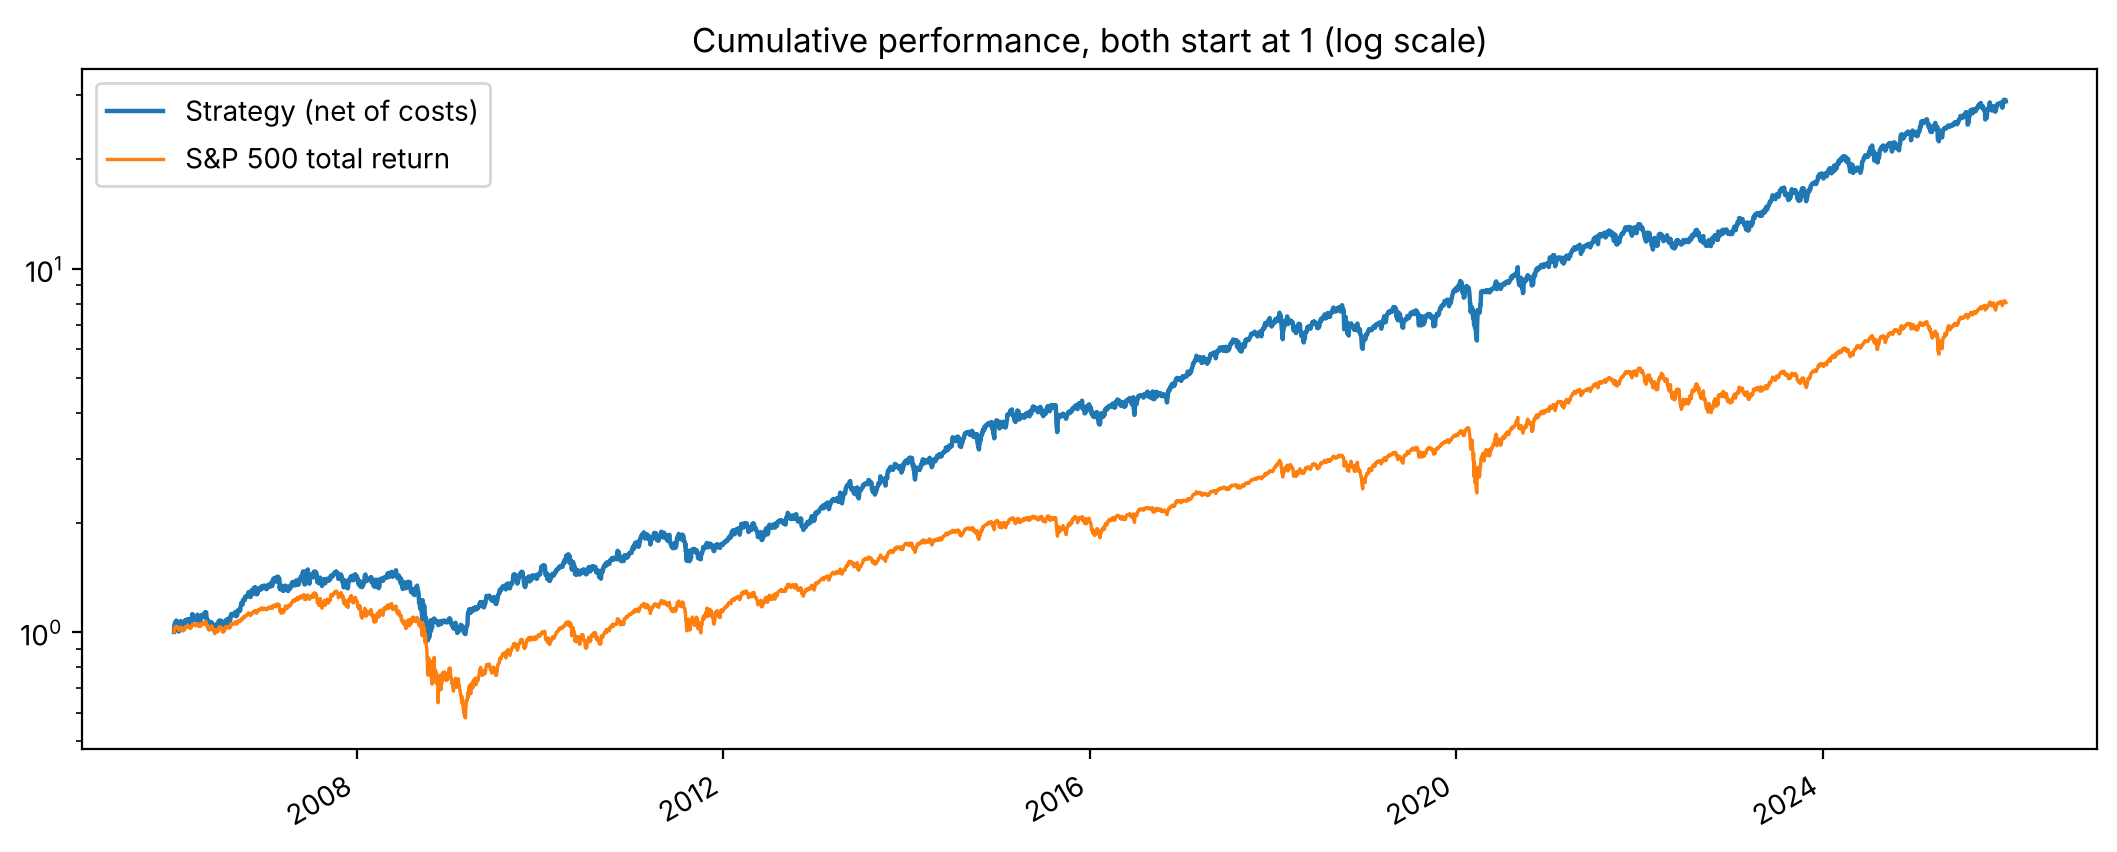

$1 grew to: strategy 28.89, S&P 500 TR 8.06


In [10]:
def wealth(r):
    w = (1 + r).cumprod()
    return pd.concat([pd.Series(1.0, index=[w.index[0] - pd.Timedelta(days=1)]), w])

fig, ax = plt.subplots(figsize=(13, 5))
wealth(bt.net).plot(ax=ax, label='Strategy (net of costs)', lw=1.6)
wealth(bench_d).plot(ax=ax, label='S&P 500 total return', lw=1.2)
ax.set_yscale('log'); ax.set_title('Cumulative performance, both start at 1 (log scale)'); ax.legend(); plt.show()
print(f'$1 grew to: strategy {wealth(bt.net).iloc[-1]:.2f}, S&P 500 TR {wealth(bench_d).iloc[-1]:.2f}')

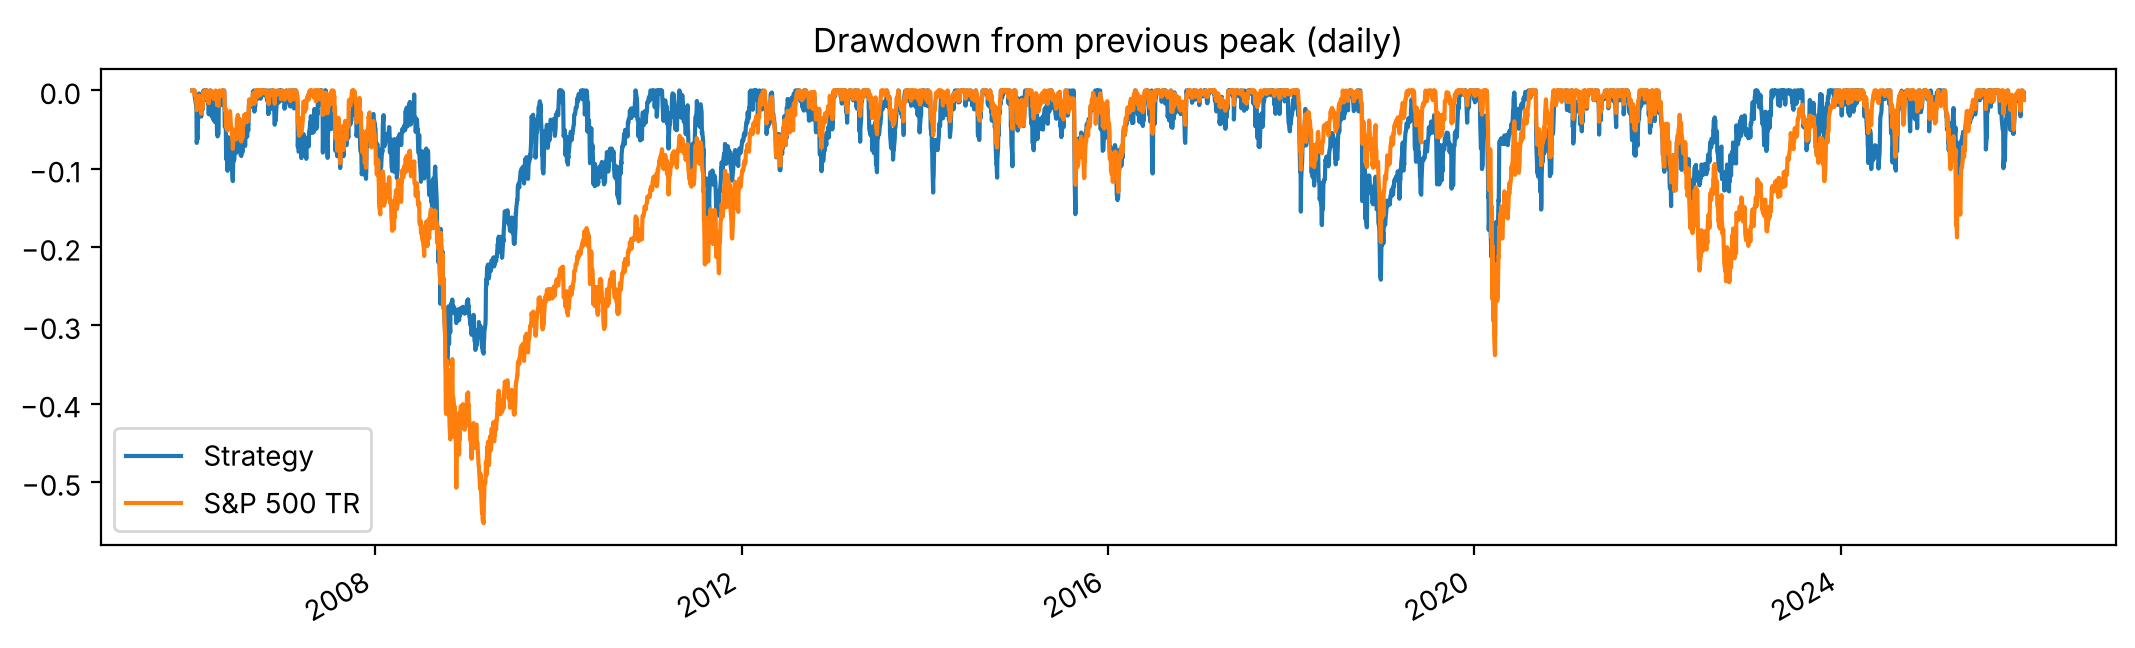

daily max drawdown: strategy -36.2%, benchmark -55.3%


In [11]:
dd = lambda r: wealth(r) / wealth(r).cummax() - 1
fig, ax = plt.subplots(figsize=(13, 3.5))
dd(bt.net).plot(ax=ax, label='Strategy'); dd(bench_d).plot(ax=ax, label='S&P 500 TR')
ax.set_title('Drawdown from previous peak (daily)'); ax.legend(); plt.show()
print('daily max drawdown: strategy {:.1%}, benchmark {:.1%}'.format(dd(bt.net).min(), dd(bench_d).min()))

## 7. Where does the profit come from? (attribution)

In [12]:
spy_only  = backtest(px, use_spy=True,  pair_size=0)      # sleeve 1 alone, pair switched off
pair_only = backtest(px, use_spy=False, pair_size=1.0)    # sleeve 2 alone, capital otherwise in T-bills
sleeves = {'Vol-managed SPY only': spy_only.net, 'Pair only (+ T-bills)': pair_only.net, 'Combined strategy': bt.net}
attr = pd.DataFrame({k: stats(monthly(v)) for k, v in sleeves.items()})
attr.loc['Ann. excess return over T-bills'] = {k: (monthly(v) - rf_m).mean() * 12 for k, v in sleeves.items()}
attr.loc['$1 grows to'] = {k: wealth(v).iloc[-1] for k, v in sleeves.items()}
print('correlation of monthly returns, SPY sleeve vs pair sleeve:',
      round(monthly(spy_only.net).corr(monthly(pair_only.net)), 3))
attr.round(4)

correlation of monthly returns, SPY sleeve vs pair sleeve: -0.083


,Vol-managed SPY only,Pair only (+ T-bills),Combined strategy
Ann. avg return,0.1293,0.0699,0.1820
Ann. volatility,0.1455,0.0777,0.1590
Sharpe ratio,0.7773,0.6939,1.0427
Alpha (ann.),0.0290,0.0530,0.0809
Alpha t-stat,1.7831,2.9999,3.7624
Beta,0.8409,0.0074,0.8485
Information ratio,0.4068,0.6845,0.8584
Max drawdown (monthly),-0.3278,-0.1459,-0.2997
Ann. excess return over T-bills,0.1131,0.0537,0.1658
$1 grows to,10.6108,3.7991,28.8869


Excess return: SPY sleeve 11.31% + pair 5.37% = 16.68% (combined actual 16.58%; the gap is compounding/interaction)
Share of excess return: SPY sleeve 68%, pair 32%
Alpha: SPY sleeve 2.90%, pair 5.30%, combined 8.09%


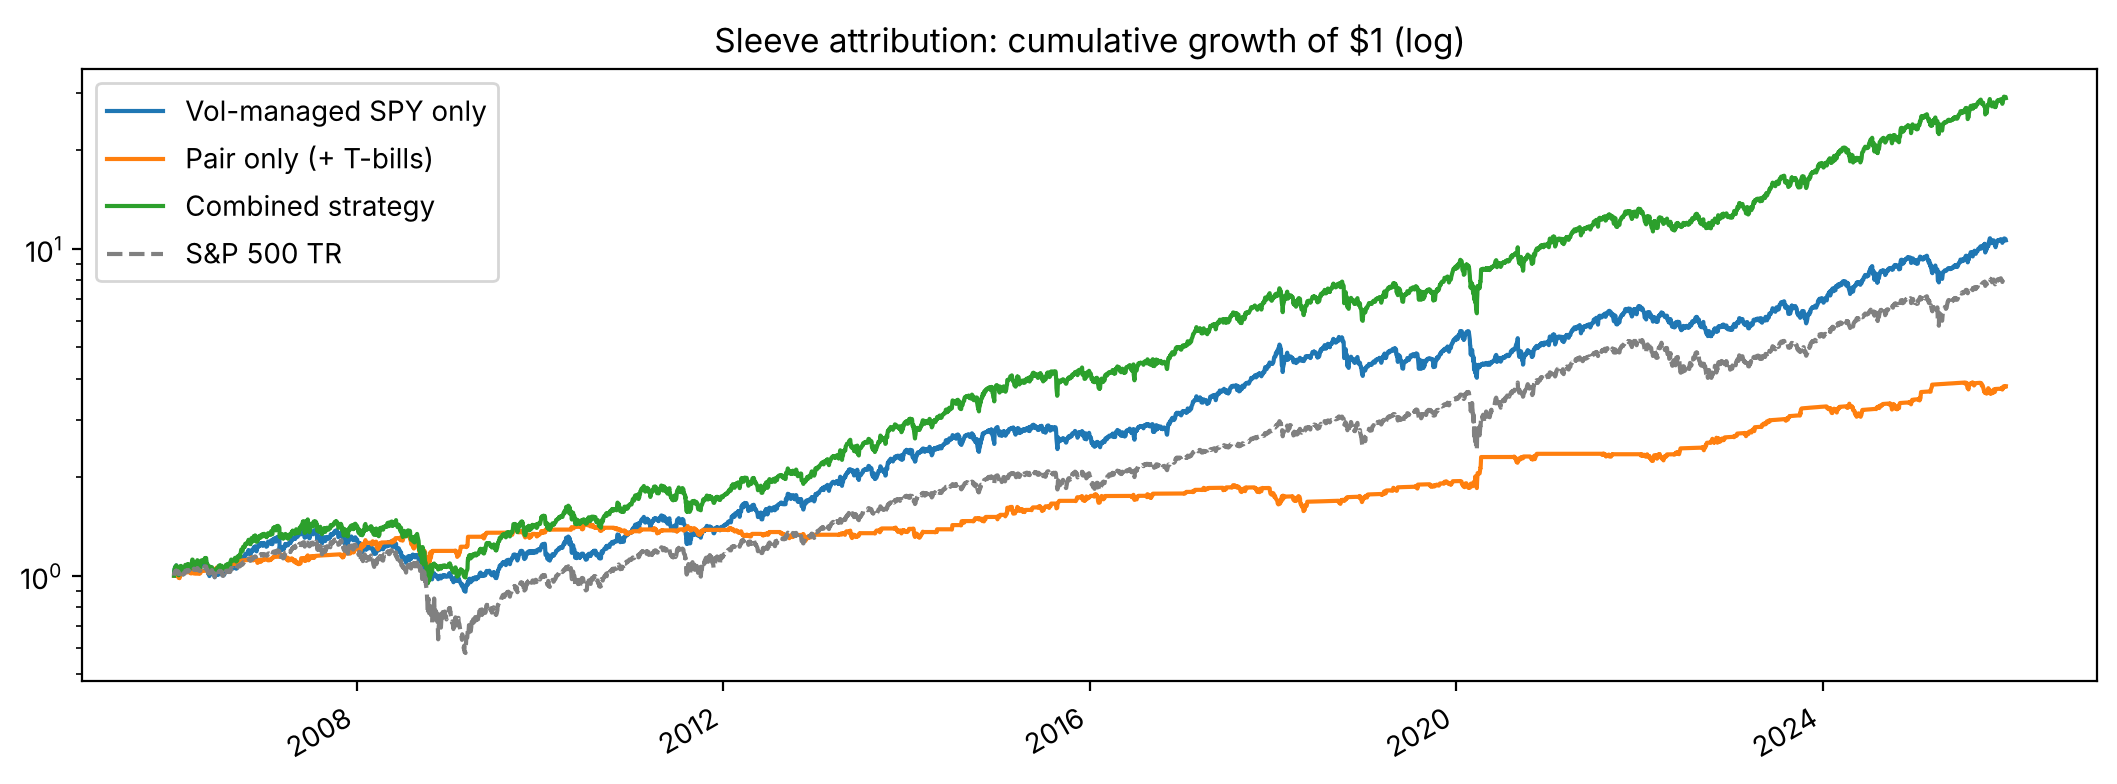

In [13]:
ex = attr.loc['Ann. excess return over T-bills']
share = ex.iloc[:2] / ex.iloc[:2].sum()
print(f"Excess return: SPY sleeve {ex.iloc[0]:.2%} + pair {ex.iloc[1]:.2%} = {ex.iloc[:2].sum():.2%} "
      f"(combined actual {ex.iloc[2]:.2%}; the gap is compounding/interaction)")
print(f"Share of excess return: SPY sleeve {share.iloc[0]:.0%}, pair {share.iloc[1]:.0%}")
al = attr.loc['Alpha (ann.)']
print(f"Alpha: SPY sleeve {al.iloc[0]:.2%}, pair {al.iloc[1]:.2%}, combined {al.iloc[2]:.2%}")
fig, ax = plt.subplots(figsize=(13, 4.5))
for k, v in sleeves.items(): wealth(v).plot(ax=ax, label=k)
wealth(bench_d).plot(ax=ax, label='S&P 500 TR', ls='--', c='grey')
ax.set_yscale('log'); ax.set_title('Sleeve attribution: cumulative growth of $1 (log)'); ax.legend(); plt.show()

## 8. Implementation: turnover, leverage and costs

In [14]:
years = len(bt) / 252
impl = pd.Series({
    'Turnover per year (x equity)': bt.turnover.sum() / years,
    'Annual cost drag (gross - net)': (bt.gross - bt.net).sum() / years,
    'Avg SPY exposure': bt.w_spy.mean(),
    'Avg gross exposure': bt.gross_exposure.mean(),
    'Max gross exposure': bt.gross_exposure.max(),
    'Pair trades opened': int(((pos != 0) & (pos.shift() == 0)).loc[START:END].sum()),
})
print(impl.round(3).to_string())

be = {c: stats(monthly(backtest(px, cost=c / 1e4).net))['Sharpe ratio'] for c in [0, 5, 10, 20, 30, 50]}
print('\nSharpe ratio by cost per unit traded (bp):', {k: round(float(v), 2) for k, v in be.items()})

Turnover per year (x equity)       25.227
Annual cost drag (gross - net)      0.025
Avg SPY exposure                    1.202
Avg gross exposure                  2.045
Max gross exposure                  4.427
Pair trades opened                105.000



Sharpe ratio by cost per unit traded (bp): {0: 1.2, 5: 1.12, 10: 1.04, 20: 0.88, 30: 0.72, 50: 0.4}


## 9. Robustness

In [15]:
rob = pd.DataFrame({
    'Base case':                 stats(strat_m),
    'Execution lag 2 days':      stats(monthly(backtest(px, lag=2).net)),
    f'In-sample ..{IS_END[:4]}': stats(strat_m.loc[:IS_END]),
    f'Out-of-sample {int(IS_END[:4]) + 1}..': stats(strat_m.loc[IS_END:].iloc[1:]),
}).loc[['Ann. avg return', 'Ann. volatility', 'Sharpe ratio', 'Alpha (ann.)', 'Beta', 'Information ratio']]
rob.round(4)

,Base case,Execution lag 2 days,In-sample ..2015,Out-of-sample 2016..
Ann. avg return,0.1820,0.1714,0.1550,0.2090
Ann. volatility,0.1590,0.1581,0.1529,0.1651
Sharpe ratio,1.0427,0.9826,0.9411,1.1358
Alpha (ann.),0.0809,0.0723,0.0861,0.0736
Beta,0.8485,0.8283,0.8138,0.8836
Information ratio,0.8584,0.7491,0.9414,0.7589


In [16]:
grid = pd.DataFrame({w: {zi: stats(monthly(backtest(px, use_spy=False, pair_kw=dict(win=w, z_in=zi)).net))['Sharpe ratio']
                         for zi in [1.5, 2.0, 2.5]} for w in [40, 60, 90, 120]}).T
grid.index.name, grid.columns.name = 'window (days)', 'entry z'
print('Pair sleeve alone, net Sharpe ratio across parameter choices (base case: 60 days, z = 2.0):')
grid.round(2)

Pair sleeve alone, net Sharpe ratio across parameter choices (base case: 60 days, z = 2.0):


entry z,1.5,2.0,2.5
window (days),,,
40,-0.07,0.38,0.23
60,0.49,0.69,0.59
90,0.69,0.59,0.83
120,0.76,0.80,0.80


In [17]:
yearly = pd.DataFrame({'Strategy': (1 + bt.net).groupby(bt.index.year).prod() - 1,
                       'SPY sleeve': (1 + spy_only.net).groupby(spy_only.index.year).prod() - 1,
                       'Pair sleeve': (1 + pair_only.net).groupby(pair_only.index.year).prod() - 1,
                       'S&P 500 TR': (1 + bench_d).groupby(bench_d.index.year).prod() - 1})
print('years strategy beat benchmark:', (yearly.Strategy > yearly['S&P 500 TR']).sum(), 'of', len(yearly))
(yearly * 100).round(1)

years strategy beat benchmark: 17 of 20


,Strategy,SPY sleeve,Pair sleeve,S&P 500 TR
Date,,,,
2006,33.3,24.6,12.2,15.8
2007,6.8,3.8,7.4,5.5
2008,-24.6,-22.5,-1.2,-37.0
2009,34.1,19.1,12.9,26.5
2010,14.7,13.5,0.9,15.1
2011,5.4,3.7,1.9,2.1
2012,18.1,22.1,-3.4,16.0
2013,44.6,41.6,2.3,32.4
2014,26.1,13.7,11.4,13.7


## 10. Risks and limitations (see prospectus for discussion)
* **Selection bias.** XLU/XLP was chosen from a small set of candidate pairs (KO/PEP, XOM/CVX, HD/LOW, EWA/EWC, XLU/XLP, XLK/XLY), with the full sample in view. Mitigations: the split check in §9, the parameter grid, and the fact that the parameters (60-day window, ±2σ entry, 15% vol target, 21 days) are textbook defaults rather than optimised values. They are not the best values in the grid.
* **Survivorship.** SPY, XLU and XLP have traded continuously since 1998 and are diversified sector/index funds, so no delisted constituents are missing from the sample.
* **Leverage and shorting.** Gross exposure can reach 2× SPY + 2× pair legs (see §8). Clients need a margin account. Borrowing and borrow fees are modelled at fixed spreads.
* **Concentration.** Equity risk is a single index (US large caps). The pair concentrates in two US defensive sectors.
* **Regime risk.** Volatility timing can lag sudden crashes (exposure is reset monthly). The pair can stop mean-reverting if utilities and staples decouple structurally.
* **Data.** ^IRX is a discount-basis yield used as an approximation of the T-bill return. Yahoo data is not point-in-time audited.

## Generative-AI disclosure
_TODO (group to complete and verify):_ Claude Code (Anthropic) was used to screen candidate non-momentum strategies in a separate sandbox (`sandbox/` folder in the repository) and to write and debug this notebook. All outputs were checked by: the truncation test for look-ahead (§5), the SPY vs ^SP500TR sanity check (§2), gross-vs-net and cost-breakeven analysis (§8), and re-running the notebook in a fresh Colab session. Instructor approval for AI-assisted strategy screening: _TODO_.